In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


In [63]:
df.columns

Index(['listing_id', 'neighbourhood', 'room_type', 'property_type', 'latitude',
       'longitude', 'accommodates', 'bedrooms', 'beds', 'price',
       'minimum_nights', 'availability_365', 'number_of_reviews',
       'number_of_reviews_ltm', 'reviews_per_month', 'review_scores_rating',
       'host_is_superhost', 'calculated_host_listings_count', 'weight'],
      dtype='object')

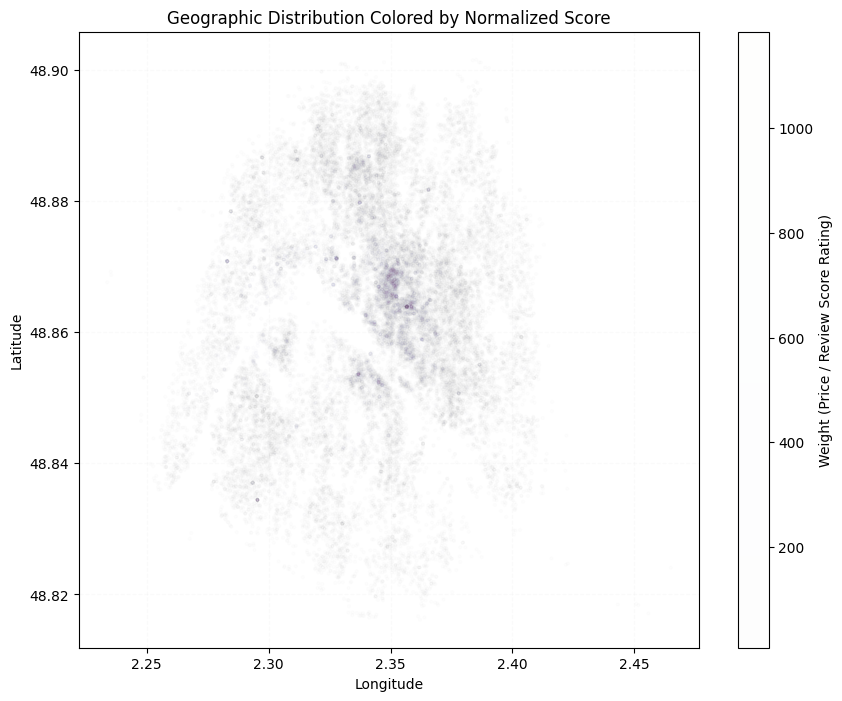

In [61]:
df = pd.read_csv('paris_listings.csv')
df.columns.to_list()
df['weight'] = df['price'] / df['review_scores_rating']

plt.figure(figsize=(10, 8))
scatter = plt.scatter(
    x=df['longitude'], 
    y=df['latitude'], 
    c=df['weight'], 
    cmap='viridis',  # You can change to 'plasma', 'coolwarm', etc.
    alpha=0.007, 
    s=5
)

# Add colorbar and labels
cbar = plt.colorbar(scatter)
cbar.set_label('Weight (Price / Review Score Rating)')

plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.title('Geographic Distribution Colored by Normalized Score')
plt.grid(True, linestyle='--', alpha=0.05)
plt.show()


Cluster sizes:
 cluster
 0     25050
-1      2753
 5        15
 26       14
 2        12
 8        11
 27        8
 3         8
 12        8
 25        8
 6         8
 23        8
 18        7
 9         7
 31        7
 15        7
 17        7
 38        7
 4         7
 35        7
 13        6
 16        6
 11        6
 45        6
 32        6
 7         6
 24        6
 40        5
 39        5
 34        5
 48        5
 29        5
 14        5
 49        5
 22        5
 42        5
 1         5
 37        5
 47        4
 51        4
 52        4
 19        4
 10        4
 20        4
 43        4
 46        4
 21        3
 33        3
 28        3
 41        3
 30        2
 50        2
 36        2
 44        2
Name: count, dtype: int64
Saved cluster labels to labels.csv


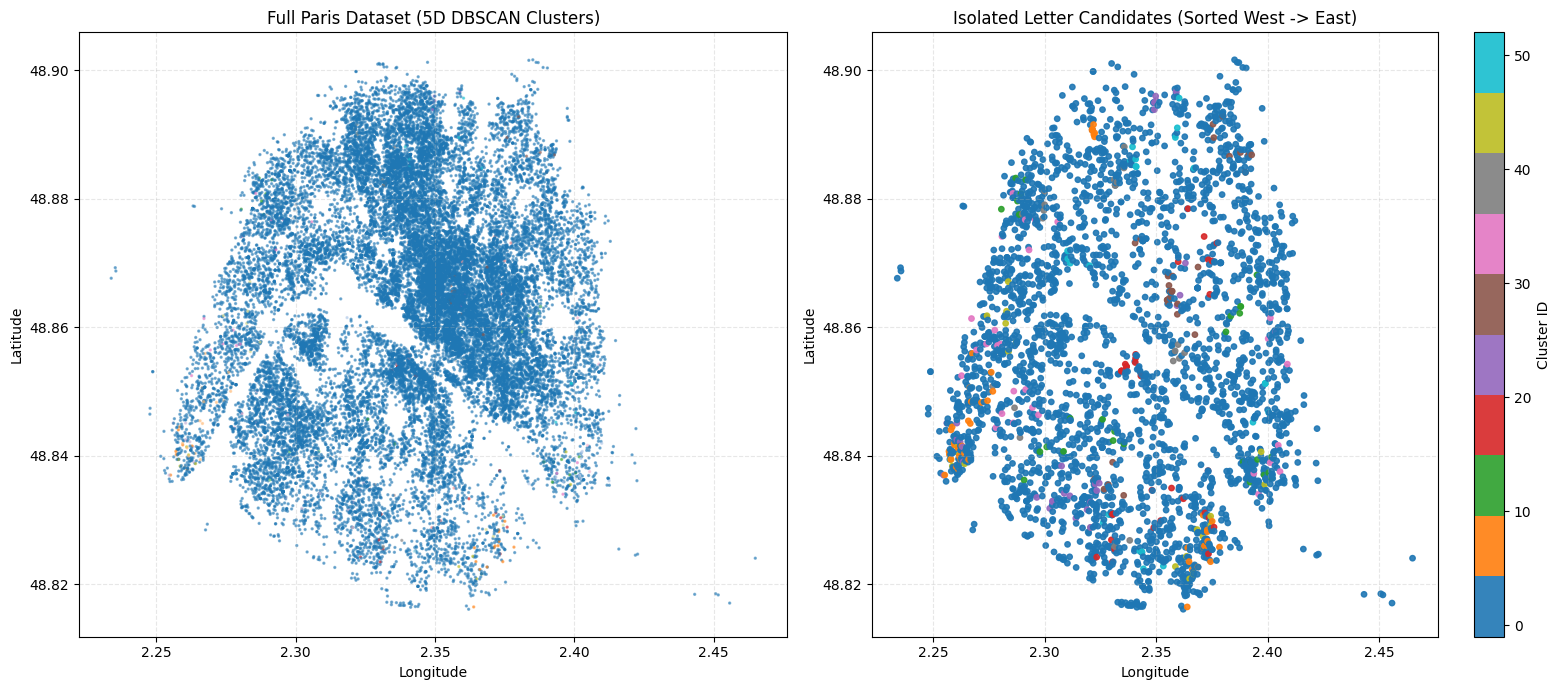



In [70]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Load the dataset
# Update the filename if needed
df = pd.read_csv('paris_listings.csv')

# 2. Select the 5 traveler features
features = ['latitude', 'longitude', 'price', 'reviews_per_month', 'availability_365']
X = df[features].copy()

# Handle missing values safely (keep track of original index)
X['reviews_per_month'] = X['reviews_per_month'].fillna(0)
X = X.dropna()

# 3. Apply log(1 + x) transformation to skewed features
X_transformed = X.copy()
X_transformed['price'] = np.log1p(X_transformed['price'])
X_transformed['reviews_per_month'] = np.log1p(X_transformed['reviews_per_month'])

# 4. Standardize all five columns
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_transformed)

# 5. Run DBSCAN in 5D feature space
# Adjust eps (e.g., 0.3 to 0.7) and min_samples if needed to cleanly separate the letters
dbscan = DBSCAN(eps=0.5, min_samples=5)
X['cluster'] = dbscan.fit_predict(X_scaled)

# Check cluster counts to identify the main city cluster
cluster_counts = X['cluster'].value_counts()
print("Cluster sizes:\n", cluster_counts)

# 6. Filter out the main Paris cluster (the largest cluster)
main_cluster = cluster_counts.idxmax()
isolated_points = X[X['cluster'] != main_cluster].copy()

# Sort isolated points from west to east (by longitude) to read letters in order
isolated_points = isolated_points.sort_values(by='longitude')

# Save the isolated points and cluster labels for submission (labels.csv)
output_df = df.loc[X.index].copy()
output_df['cluster'] = X['cluster']
output_df['is_letter_candidate'] = output_df['cluster'] != main_cluster
output_df.to_csv('labels.csv', index=False)
print("Saved cluster labels to labels.csv")

# 7. Plot the full city vs. isolated letter candidates
fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Left plot: Full map colored by cluster
axes[0].scatter(
    X['longitude'], X['latitude'],
    c=X['cluster'], cmap='tab20', s=2, alpha=0.5
)
axes[0].set_title("Full Paris Dataset (5D DBSCAN Clusters)")
axes[0].set_xlabel("Longitude")
axes[0].set_ylabel("Latitude")
axes[0].grid(True, linestyle='--', alpha=0.3)

# Right plot: Only isolated points (excluding main city cluster)
scatter = axes[1].scatter(
    isolated_points['longitude'], isolated_points['latitude'],
    c=isolated_points['cluster'], cmap='tab10', s=15, alpha=0.9
)
axes[1].set_title("Isolated Letter Candidates (Sorted West -> East)")
axes[1].set_xlabel("Longitude")
axes[1].set_ylabel("Latitude")
axes[1].grid(True, linestyle='--', alpha=0.3)
plt.colorbar(scatter, ax=axes[1], label="Cluster ID")

plt.tight_layout()
plt.savefig('clustered_word.png', dpi=300)
plt.show()

# 8. Optional: Zoom into each non-main cluster individually (ordered by mean longitude)
sub_clusters = (
    isolated_points[isolated_points['cluster'] != -1]
    .groupby('cluster')['longitude']
    .mean()
    .sort_values()
    .index
)

if len(sub_clusters) > 0:
    fig, axes = plt.subplots(1, len(sub_clusters), figsize=(3 * len(sub_clusters), 4))
    if len(sub_clusters) == 1:
        axes = [axes]
    for ax, cid in zip(axes, sub_clusters):
        subset = isolated_points[isolated_points['cluster'] == cid]
        ax.scatter(subset['longitude'], subset['latitude'], s=20, color='black')
        ax.set_title(f"Cluster {cid}\n(n={len(subset)})")
        ax.set_aspect('equal', adjustable='datalim')
        ax.axis('off')
    plt.tight_layout()
    plt.savefig('individual_letters.png', dpi=300)
    plt.show()